In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import pandas as pd
df = pd.read_csv("Automobile_data.csv")
print("Dataset loaded successfully")


Dataset loaded successfully


In [4]:
df.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.4,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.4,8.0,115,5500,18,22,17450


In [6]:
print(df.shape)

(205, 26)


In [7]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized-losses  205 non-null    object 
 2   make               205 non-null    object 
 3   fuel-type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num-of-doors       205 non-null    object 
 6   body-style         205 non-null    object 
 7   drive-wheels       205 non-null    object 
 8   engine-location    205 non-null    object 
 9   wheel-base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb-weight        205 non-null    int64  
 14  engine-type        205 non-null    object 
 15  num-of-cylinders   205 non-null    object 
 16  engine-size        205 non

# Replace missing values

In [8]:
df = df.replace('?', np.nan)

print(df.isnull().sum())

symboling             0
normalized-losses    41
make                  0
fuel-type             0
aspiration            0
num-of-doors          2
body-style            0
drive-wheels          0
engine-location       0
wheel-base            0
length                0
width                 0
height                0
curb-weight           0
engine-type           0
num-of-cylinders      0
engine-size           0
fuel-system           0
bore                  4
stroke                4
compression-ratio     0
horsepower            2
peak-rpm              2
city-mpg              0
highway-mpg           0
price                 4
dtype: int64


# Convert technical columns into numeric format

In [10]:
cols = ['normalized-losses', 'bore', 'stroke',
        'horsepower', 'peak-rpm', 'price']

for col in cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Handle missing values

In [11]:
df['normalized-losses'] = df['normalized-losses'].fillna(
    df['normalized-losses'].median())

df['bore'] = df['bore'].fillna(df['bore'].median())

df['stroke'] = df['stroke'].fillna(df['stroke'].median())

df['horsepower'] = df['horsepower'].fillna(
    df['horsepower'].median())

df['peak-rpm'] = df['peak-rpm'].fillna(
    df['peak-rpm'].median())

df['price'] = df['price'].fillna(df['price'].median())

df['num-of-doors'] = df['num-of-doors'].fillna(
    df['num-of-doors'].mode()[0])

print(df.isnull().sum())

symboling            0
normalized-losses    0
make                 0
fuel-type            0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               0
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
dtype: int64


# Handle missing engine size

In [13]:
df['engine-size'] = df['engine-size'].fillna(
    df['engine-size'].median())

# Calculate power-to-weight ratio

In [14]:
df['power_to_weight'] = (
    df['horsepower'] / (df['curb-weight'] / 1000)
)

print(df[['make', 'horsepower',
          'curb-weight', 'power_to_weight']].head())

          make  horsepower  curb-weight  power_to_weight
0  alfa-romero       111.0         2548        43.563579
1  alfa-romero       111.0         2548        43.563579
2  alfa-romero       154.0         2823        54.551895
3         audi       102.0         2337        43.645700
4         audi       115.0         2824        40.722380


# Visualize engine size

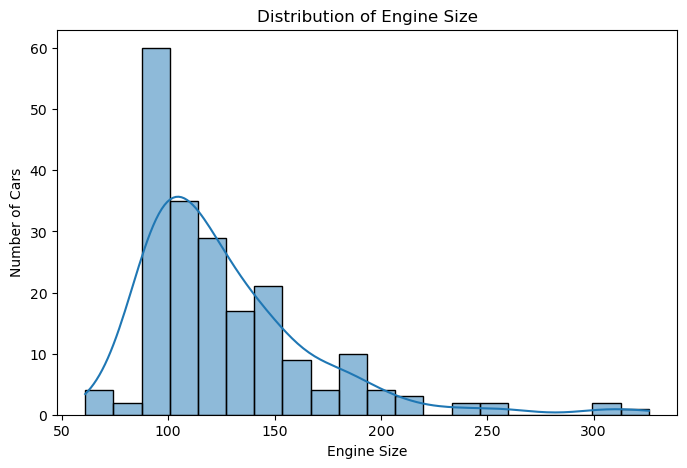

In [15]:
plt.figure(figsize=(8,5))

sns.histplot(df['engine-size'], bins=20, kde=True)

plt.title("Distribution of Engine Size")
plt.xlabel("Engine Size")
plt.ylabel("Number of Cars")

plt.show()

# Visualize horsepower and power-to-weight ratio

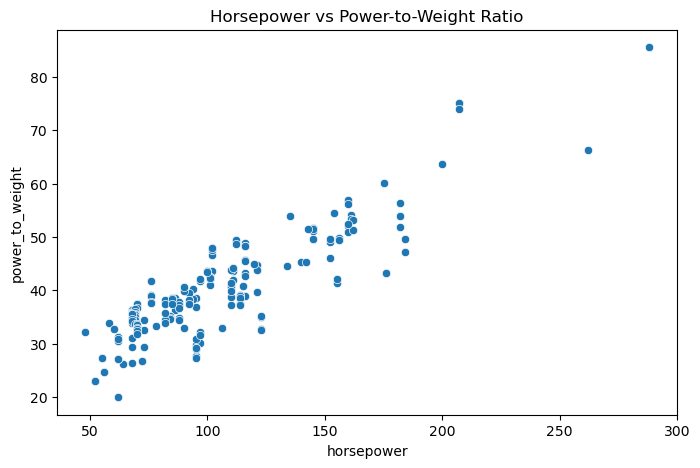

In [16]:
plt.figure(figsize=(8,5))

sns.scatterplot(x='horsepower',
                y='power_to_weight',
                data=df)

plt.title("Horsepower vs Power-to-Weight Ratio")
plt.show()

# Check cleaned dataset

In [17]:
print(df.head())

print("Missing Values:")
print(df.isnull().sum())

   symboling  normalized-losses         make fuel-type aspiration  \
0          3              115.0  alfa-romero       gas        std   
1          3              115.0  alfa-romero       gas        std   
2          1              115.0  alfa-romero       gas        std   
3          2              164.0         audi       gas        std   
4          2              164.0         audi       gas        std   

  num-of-doors   body-style drive-wheels engine-location  wheel-base  ...  \
0          two  convertible          rwd           front        88.6  ...   
1          two  convertible          rwd           front        88.6  ...   
2          two    hatchback          rwd           front        94.5  ...   
3         four        sedan          fwd           front        99.8  ...   
4         four        sedan          4wd           front        99.4  ...   

   fuel-system  bore  stroke  compression-ratio horsepower peak-rpm  city-mpg  \
0         mpfi  3.47    2.68             

# Automobile – Pricing & Performance Trade-off Analysis

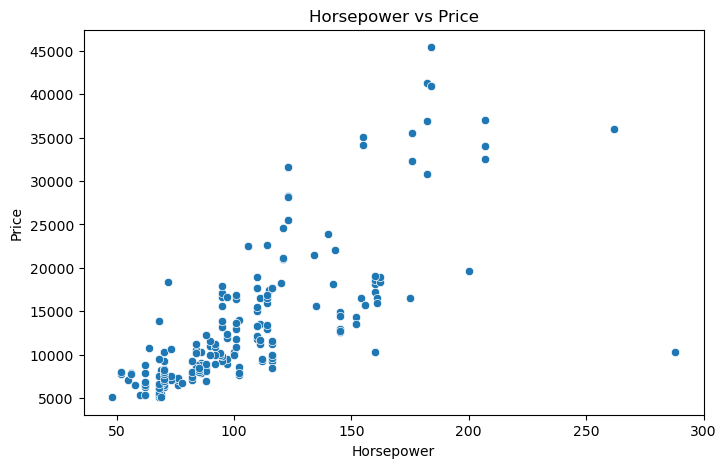

In [18]:
plt.figure(figsize=(8,5))

sns.scatterplot(x='horsepower',
                y='price',
                data=df)

plt.title("Horsepower vs Price")
plt.xlabel("Horsepower")
plt.ylabel("Price")

plt.show()

# Engine Size vs MPG

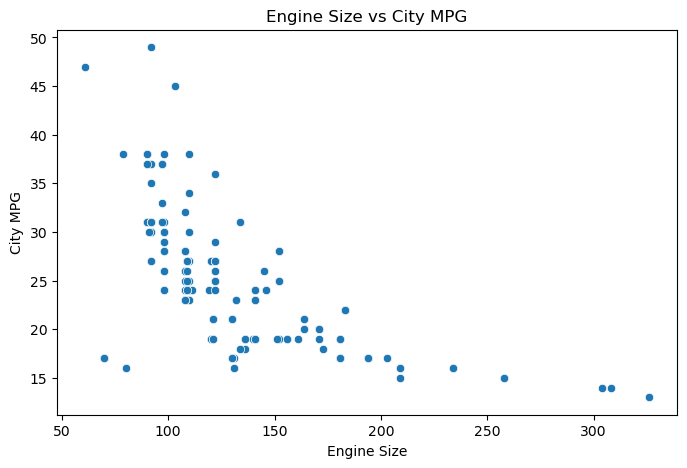

In [19]:
plt.figure(figsize=(8,5))

sns.scatterplot(x='engine-size',
                y='city-mpg',
                data=df)

plt.title("Engine Size vs City MPG")
plt.xlabel("Engine Size")
plt.ylabel("City MPG")

plt.show()

# Budget and Premium Brand Segmentation

In [20]:
brand_price = df.groupby('make')['price'].mean()

print(brand_price)

make
alfa-romero      15498.333333
audi             16778.571429
bmw              26118.750000
chevrolet         6007.000000
dodge             7875.444444
honda             8184.692308
isuzu             9605.750000
jaguar           34600.000000
mazda            10652.882353
mercedes-benz    33647.000000
mercury          16503.000000
mitsubishi        9239.769231
nissan           10415.666667
peugot           15489.090909
plymouth          7963.428571
porsche          27179.400000
renault           9595.000000
saab             15223.333333
subaru            8541.250000
toyota            9885.812500
volkswagen       10077.500000
volvo            18063.181818
Name: price, dtype: float64


# Classify brands

In [23]:
limit = brand_price.median()

brand_segment = brand_price.apply(
    lambda x: 'Budget' if x < limit else 'Premium'
)

print(brand_segment)

make
alfa-romero      Premium
audi             Premium
bmw              Premium
chevrolet         Budget
dodge             Budget
honda             Budget
isuzu             Budget
jaguar           Premium
mazda            Premium
mercedes-benz    Premium
mercury          Premium
mitsubishi        Budget
nissan            Budget
peugot           Premium
plymouth          Budget
porsche          Premium
renault           Budget
saab             Premium
subaru            Budget
toyota            Budget
volkswagen        Budget
volvo            Premium
Name: price, dtype: object


#  Visualize Budget vs Premium brands

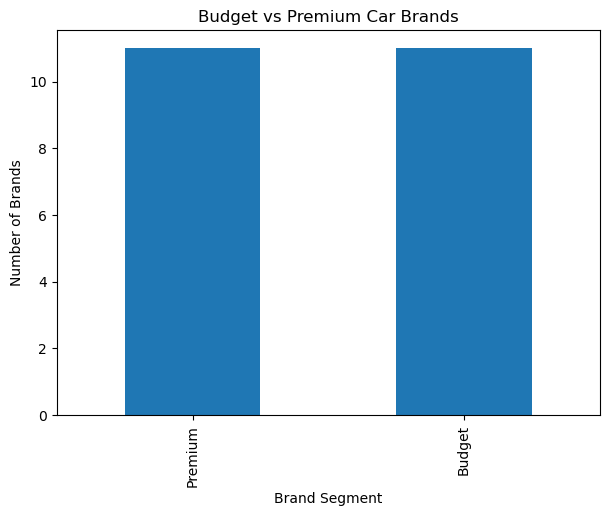

In [24]:
brand_segment.value_counts().plot(
    kind='bar',
    figsize=(7,5)
)

plt.title("Budget vs Premium Car Brands")
plt.xlabel("Brand Segment")
plt.ylabel("Number of Brands")

plt.show()

# Final result

In [25]:
print("Average Car Price:")
print(df['price'].mean())

print("\nAverage Horsepower:")
print(df['horsepower'].mean())

print("\nAverage Engine Size:")
print(df['engine-size'].mean())

print("\nBrand Segmentation:")
print(brand_segment)

Average Car Price:
13150.307317073171

Average Horsepower:
104.16585365853659

Average Engine Size:
126.90731707317073

Brand Segmentation:
make
alfa-romero      Premium
audi             Premium
bmw              Premium
chevrolet         Budget
dodge             Budget
honda             Budget
isuzu             Budget
jaguar           Premium
mazda            Premium
mercedes-benz    Premium
mercury          Premium
mitsubishi        Budget
nissan            Budget
peugot           Premium
plymouth          Budget
porsche          Premium
renault           Budget
saab             Premium
subaru            Budget
toyota            Budget
volkswagen        Budget
volvo            Premium
Name: price, dtype: object
